In [13]:
import cv2
import matplotlib.pyplot as plt
import numpy as np


<div class="alert alert-block alert-info">
<b>Tip:</b> Hier Preprocessing magic einfügen um Bild korrekt zu croppen
</div>

In [14]:
img = cv2.imread('Aufnahmen/image_22_cropped.tiff', cv2.IMREAD_GRAYSCALE)
x_start, x_end = 0, 1350
roi1 = img[100:220, 0:1350]
# roi2 = img[220:340, 0:1350]
roi2 = img[270:290, 0:1350]
roi3 = img[340:460, 0:1350]

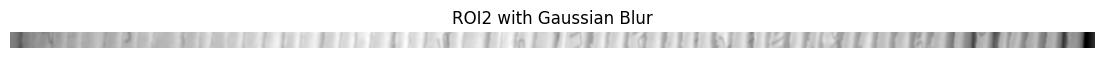

In [15]:
# Gaussian Filter on roi2
roi2_blurred = cv2.GaussianBlur(roi2, (5, 5), 0.8)

plt.figure(figsize=(14, 6))
plt.imshow(roi2_blurred, cmap='gray')
plt.title('ROI2 with Gaussian Blur')
plt.axis('off')
plt.show()

In [16]:
def sobel_edge_detection(roi):
    sobelx = cv2.Sobel(roi, cv2.CV_64F, 1, 0, ksize=3)
    sobely = cv2.Sobel(roi, cv2.CV_64F, 0, 1, ksize=3)
    gradient_magnitude = cv2.magnitude(sobelx, sobely)
    gradient_magnitude = cv2.convertScaleAbs(gradient_magnitude)
    return gradient_magnitude

def canny_edge_detection(roi):
    edges = cv2.Canny(roi, 20, 100)
    return edges

In [17]:
# Compute edge detections
roi2_gm = sobel_edge_detection(roi2)
roi2_gm_blurred = sobel_edge_detection(roi2_blurred)
roi2_canny_blurred = canny_edge_detection(roi2_blurred)
roi2_canny = canny_edge_detection(roi2)

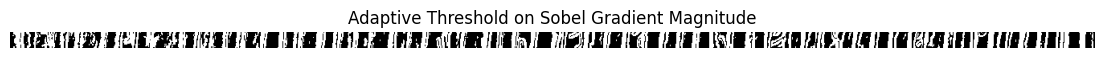

In [18]:
# Adaptive Thresholding on Sobel Gradient Magnitude
adaptive_edges = cv2.adaptiveThreshold(
    roi2_gm_blurred, 255, 
    cv2.ADAPTIVE_THRESH_MEAN_C, 
    cv2.THRESH_BINARY, 
    31, 2
)

plt.figure(figsize=(14, 6))
plt.imshow(adaptive_edges, cmap='gray')
plt.title('Adaptive Threshold on Sobel Gradient Magnitude')
plt.axis('off')
plt.show()

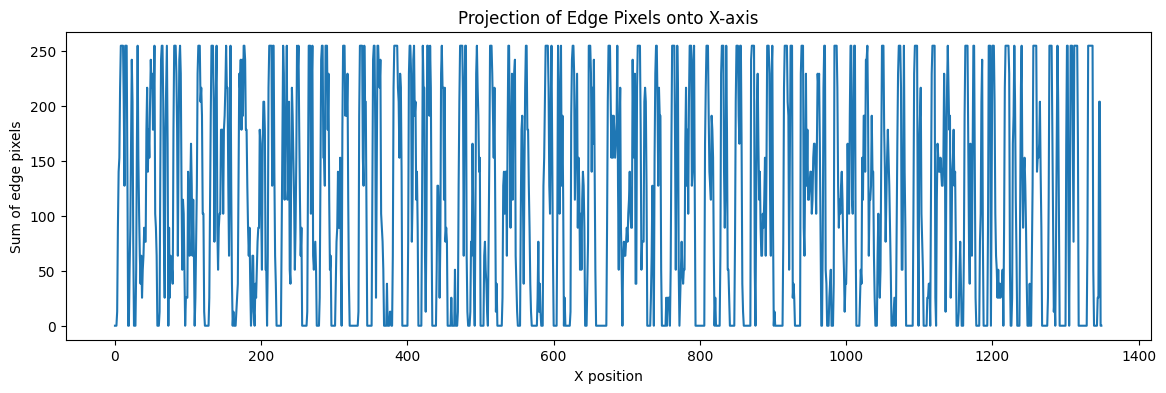

In [19]:
projection = np.sum(adaptive_edges, axis=0)/20

plt.figure(figsize=(14, 4))
plt.plot(projection)
plt.title('Projection of Edge Pixels onto X-axis')
plt.xlabel('X position')
plt.ylabel('Sum of edge pixels')
plt.show()


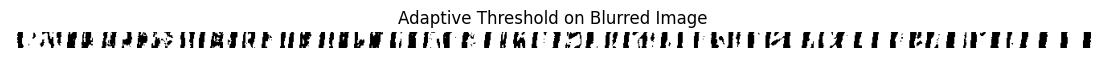

In [20]:
# Adaptive Thresholding on Sobel Gradient Magnitude
adaptive_edges = cv2.adaptiveThreshold(
    roi2_blurred, 255, 
    cv2.ADAPTIVE_THRESH_MEAN_C, 
    cv2.THRESH_BINARY, 
    17, 2
)

plt.figure(figsize=(14, 6))
plt.imshow(adaptive_edges, cmap='gray')
plt.title('Adaptive Threshold on Blurred Image')
plt.axis('off')
plt.show()

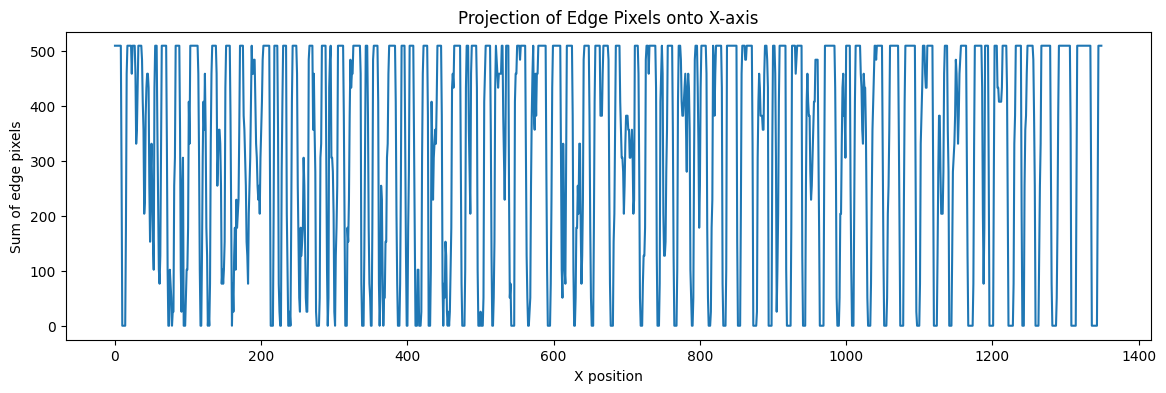

In [22]:
projection = np.sum(adaptive_edges, axis=0)/10

plt.figure(figsize=(14, 4))
plt.plot(projection)
plt.title('Projection of Edge Pixels onto X-axis')
plt.xlabel('X position')
plt.ylabel('Sum of edge pixels')
plt.show()


In [39]:
# Calculate the number of projection values below a certain threshold
# if the next projection value (or the next 5) is the same or lower, ignore it until a higher value is found

values = projection

is_zero = values == 0

# Find transitions from nonzero to zero and back
zero_segments = np.diff(is_zero.astype(int))
start_points = np.where(zero_segments == 1)[0]
end_points = np.where(zero_segments == -1)[0]

# Handle edge cases
if is_zero[0]:
    start_points = np.insert(start_points, 0, -1)
if is_zero[-1]:
    end_points = np.append(end_points, len(is_zero) - 1)

num_zero_segments = len(start_points)
print(f"Number of zero plains: {num_zero_segments}")


Number of zero plains: 66


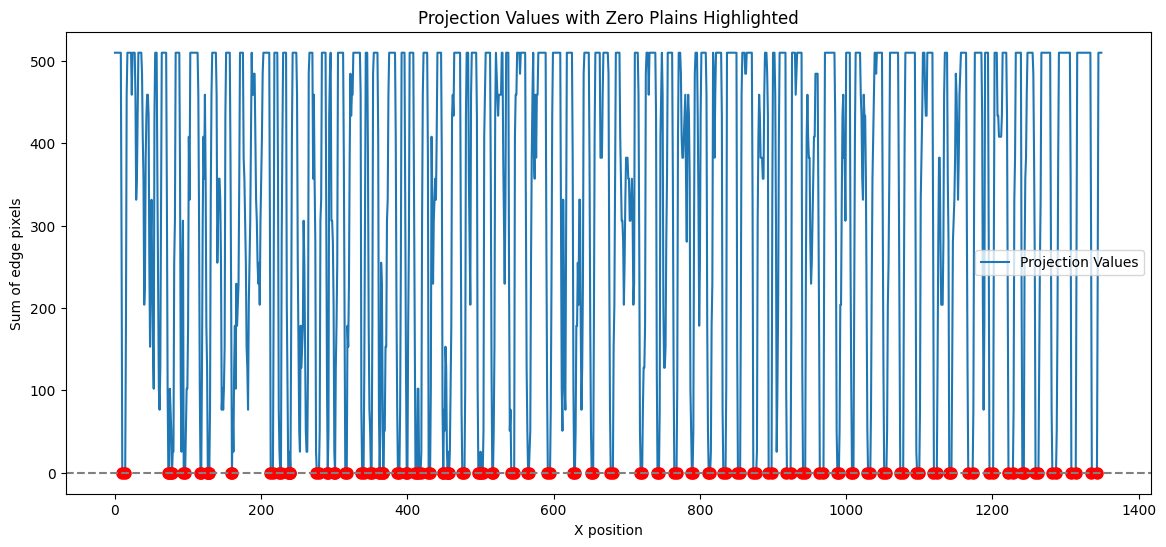

In [42]:
# Visualization
plt.figure(figsize=(14, 6))
plt.plot(values, label='Projection Values')
# Plot the zero plains as red bubbles
for start, end in zip(start_points, end_points):
    plt.plot([start, end], [0, 0], marker='o', color='red', markersize=8)

plt.title('Projection Values with Zero Plains Highlighted')
plt.xlabel('X position')
plt.ylabel('Sum of edge pixels')
# Plot a grey line at y=0
plt.axhline(0, color='grey', linestyle='--')
plt.legend()
plt.show()